## MTL Trajet: 16 Return Home Work Discretionary Patterns (Flag 16)

### Dataset Overview
Multi-user work, discretionary, and returning-home trajectories with origin/destination land-use, transport mode, timing, island-axis direction, and point speeds. The accompanying montreal_island_axis.csv defines the analytical southwest–northeast baseline used for route comparison.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Analyze how returning-home travel differs from work and discretionary travel.

Role: Urban mobility-pattern analyst


Category: Multi-user work, discretionary, and returning-home trajectories with origin/destination land-use, transport mode, timing, island-axis direction, and point speeds. The accompanying montreal_island_axis.csv defines the analytical southwest–northeast baseline used for route comparison.

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How do departure times differ among work, returning-home, and discretionary trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

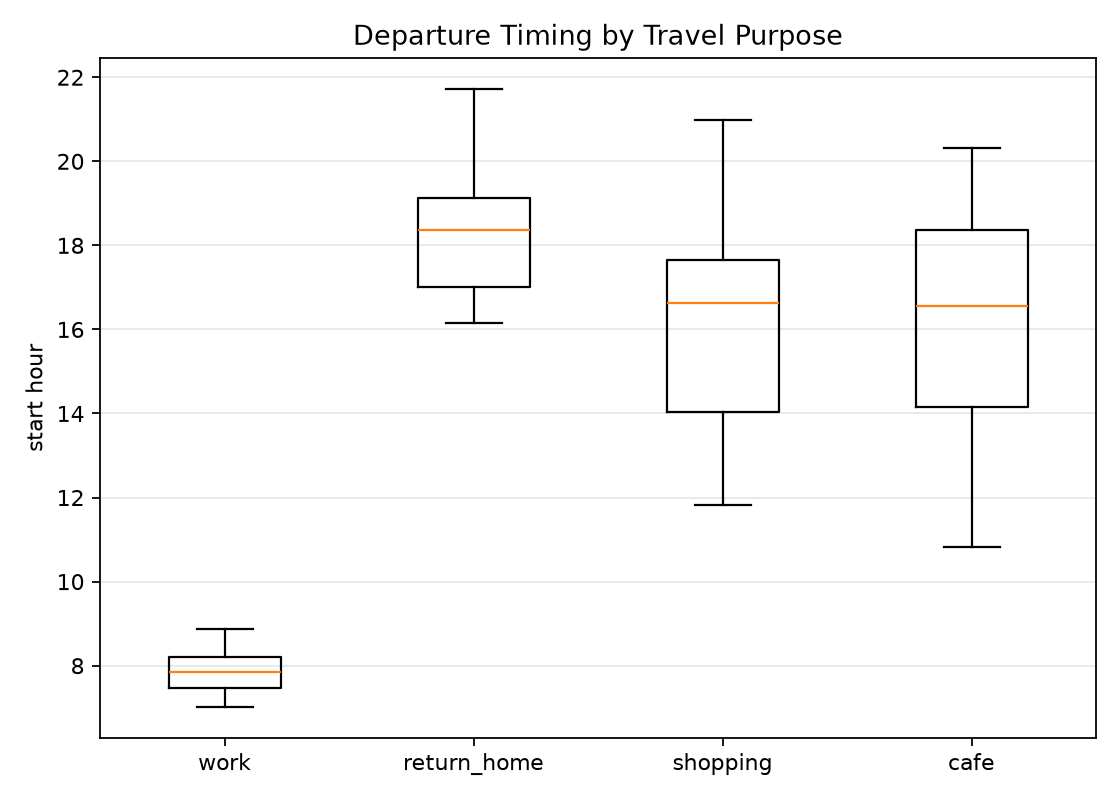

In [ ]:
df.groupby('purpose_group').start_hour.agg(['count','median','std'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/purpose_departure_time.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_departure_time",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Departure Timing by Travel Purpose",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/purpose_departure_time.png"
  },
  "question": "How do departure times differ among work, returning-home, and discretionary trips?",
  "code": "df.groupby('purpose_group').start_hour.agg(['count','median','std'])",
  "insight": "Returning-home trips are strongly concentrated in the evening rush, while work trips peak earlier and discretionary trips remain more temporally dispersed.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### **Question 2**: How do signed island-axis displacements differ among work, return-home, café, and shopping trips?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

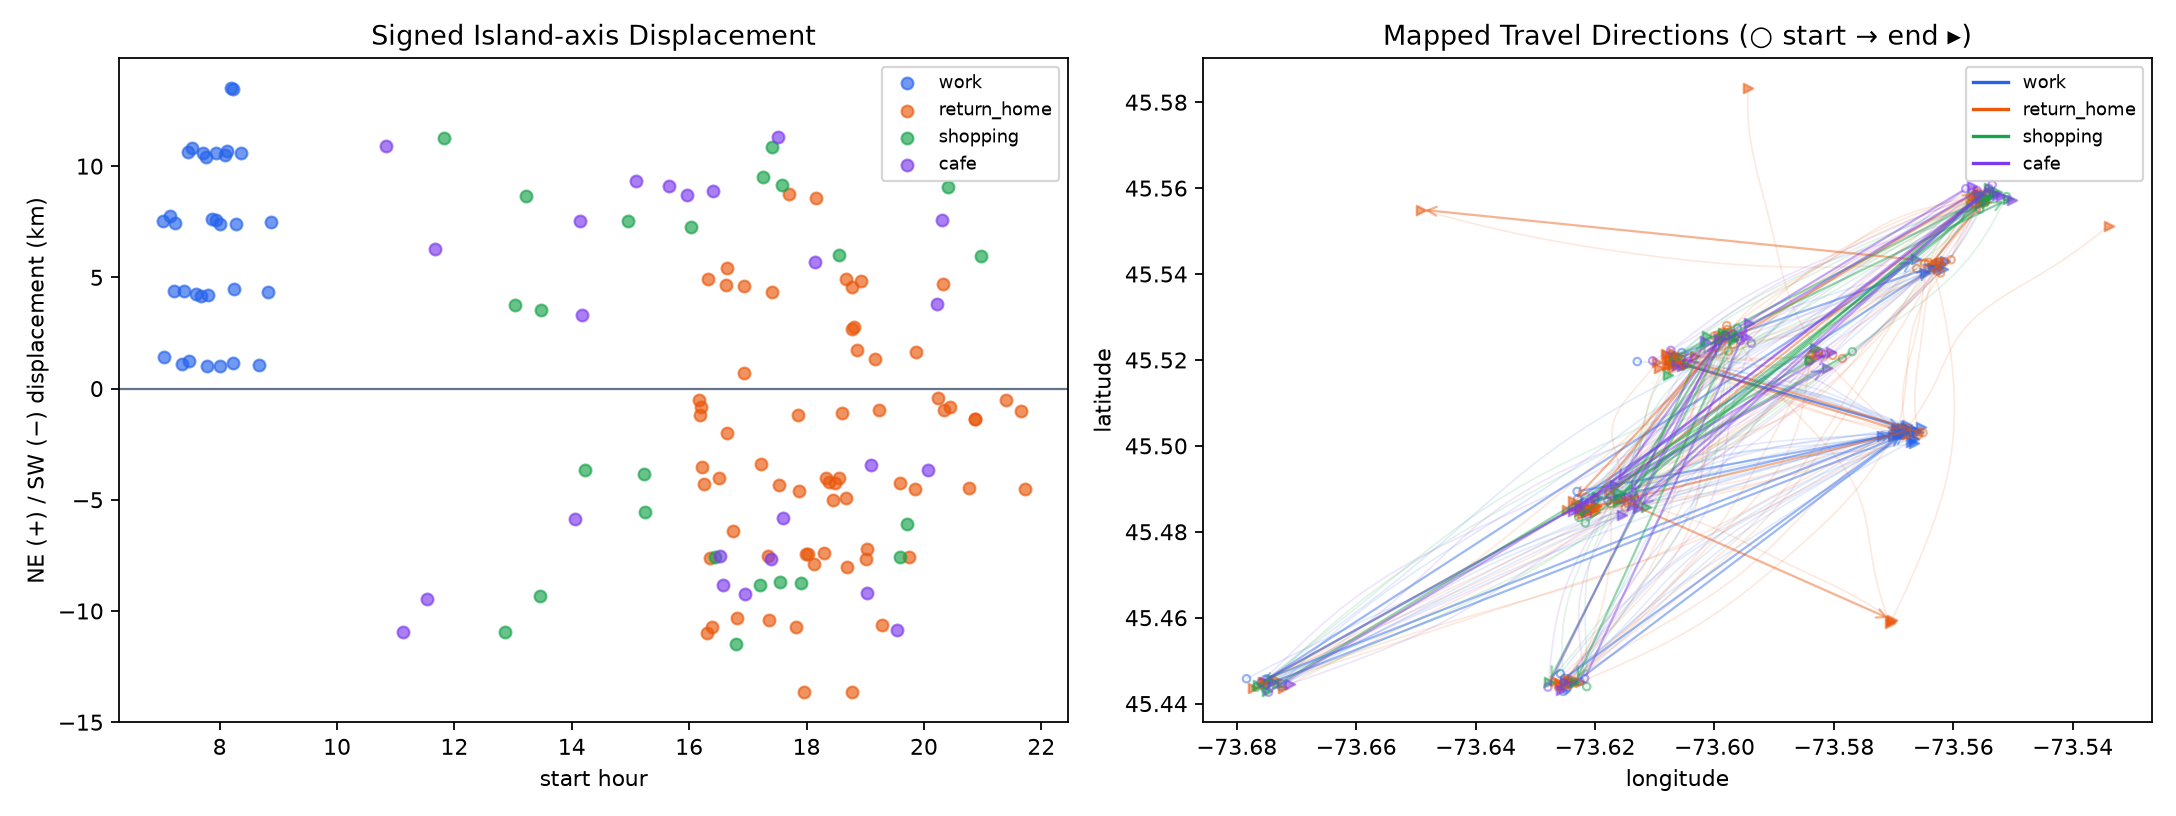

In [ ]:
axis_df = pd.read_csv('montreal_island_axis.csv'); axis_df; df.groupby('purpose_group').island_axis_projection_km.agg(['median','mean','std'])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/purpose_island_axis_direction.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "purpose_island_axis_direction",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Opposite Work and Return-home Directions",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/purpose_island_axis_direction.png"
  },
  "question": "How do signed island-axis displacements differ among work, return-home, café, and shopping trips?",
  "code": "axis_df = pd.read_csv('montreal_island_axis.csv'); axis_df; df.groupby('purpose_group').island_axis_projection_km.agg(['median','mean','std'])",
  "insight": "Work and returning-home trajectories show opposite dominant directions along Montréal's island axis, unlike café and shopping trips, which are directionally dispersed.",
  "insight_type": "group_comparison",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "gps_position",
    "island_axis_reference",
    "trajectory_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: How do home-bound distance and mode composition vary by origin land-use?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

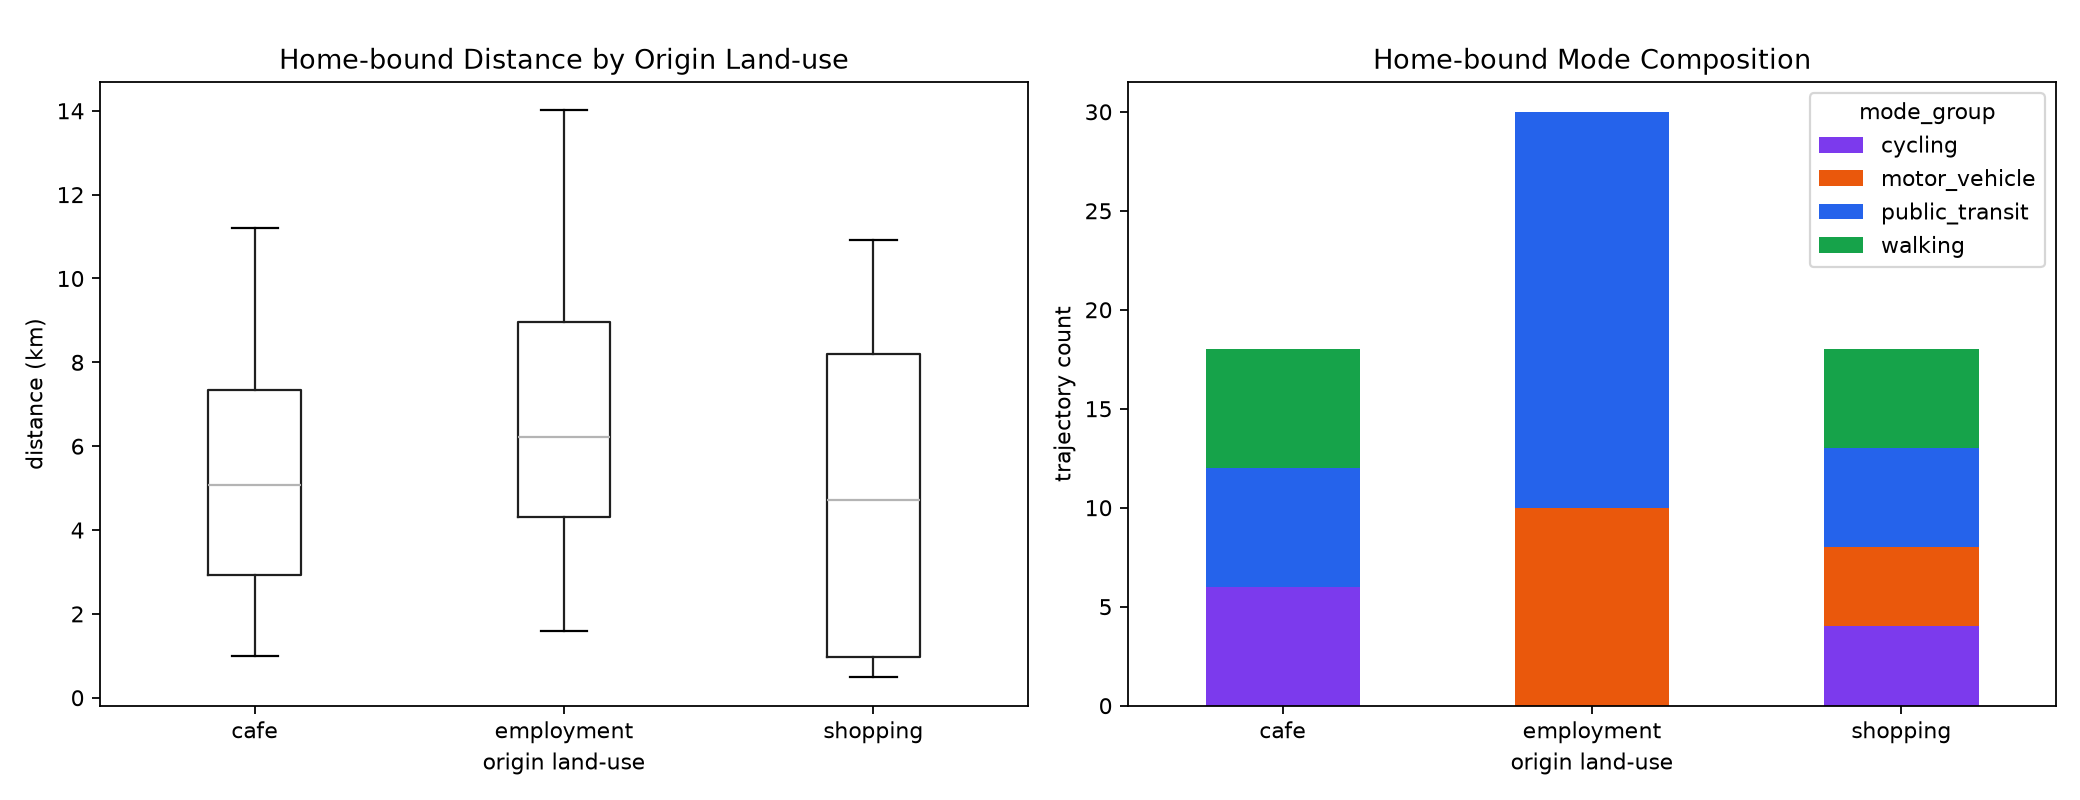

In [ ]:
df[df.purpose_group.eq('return_home')].groupby('origin_land_use').distance_km.agg(['median','mean']); pd.crosstab(df.origin_land_use,df.mode_group)
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/home_bound_origin_distance_modes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "home_origin_distance_mode",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Home-bound Distance and Mode by Origin",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/home_bound_origin_distance_modes.png"
  },
  "question": "How do home-bound distance and mode composition vary by origin land-use?",
  "code": "df[df.purpose_group.eq('return_home')].groupby('origin_land_use').distance_km.agg(['median','mean']); pd.crosstab(df.origin_land_use,df.mode_group)",
  "insight": "Home-bound trips from employment areas are longer and more mode-stable than those from shopping or café areas, which include more walking and cycling.",
  "insight_type": "factor_relationship",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "origin_land_use",
    "transport_mode",
    "gps_position",
    "trajectory_id"
  ]
}

### **Question 4**: Does the number of home destination zones decline from early to late evening within each origin land-use?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

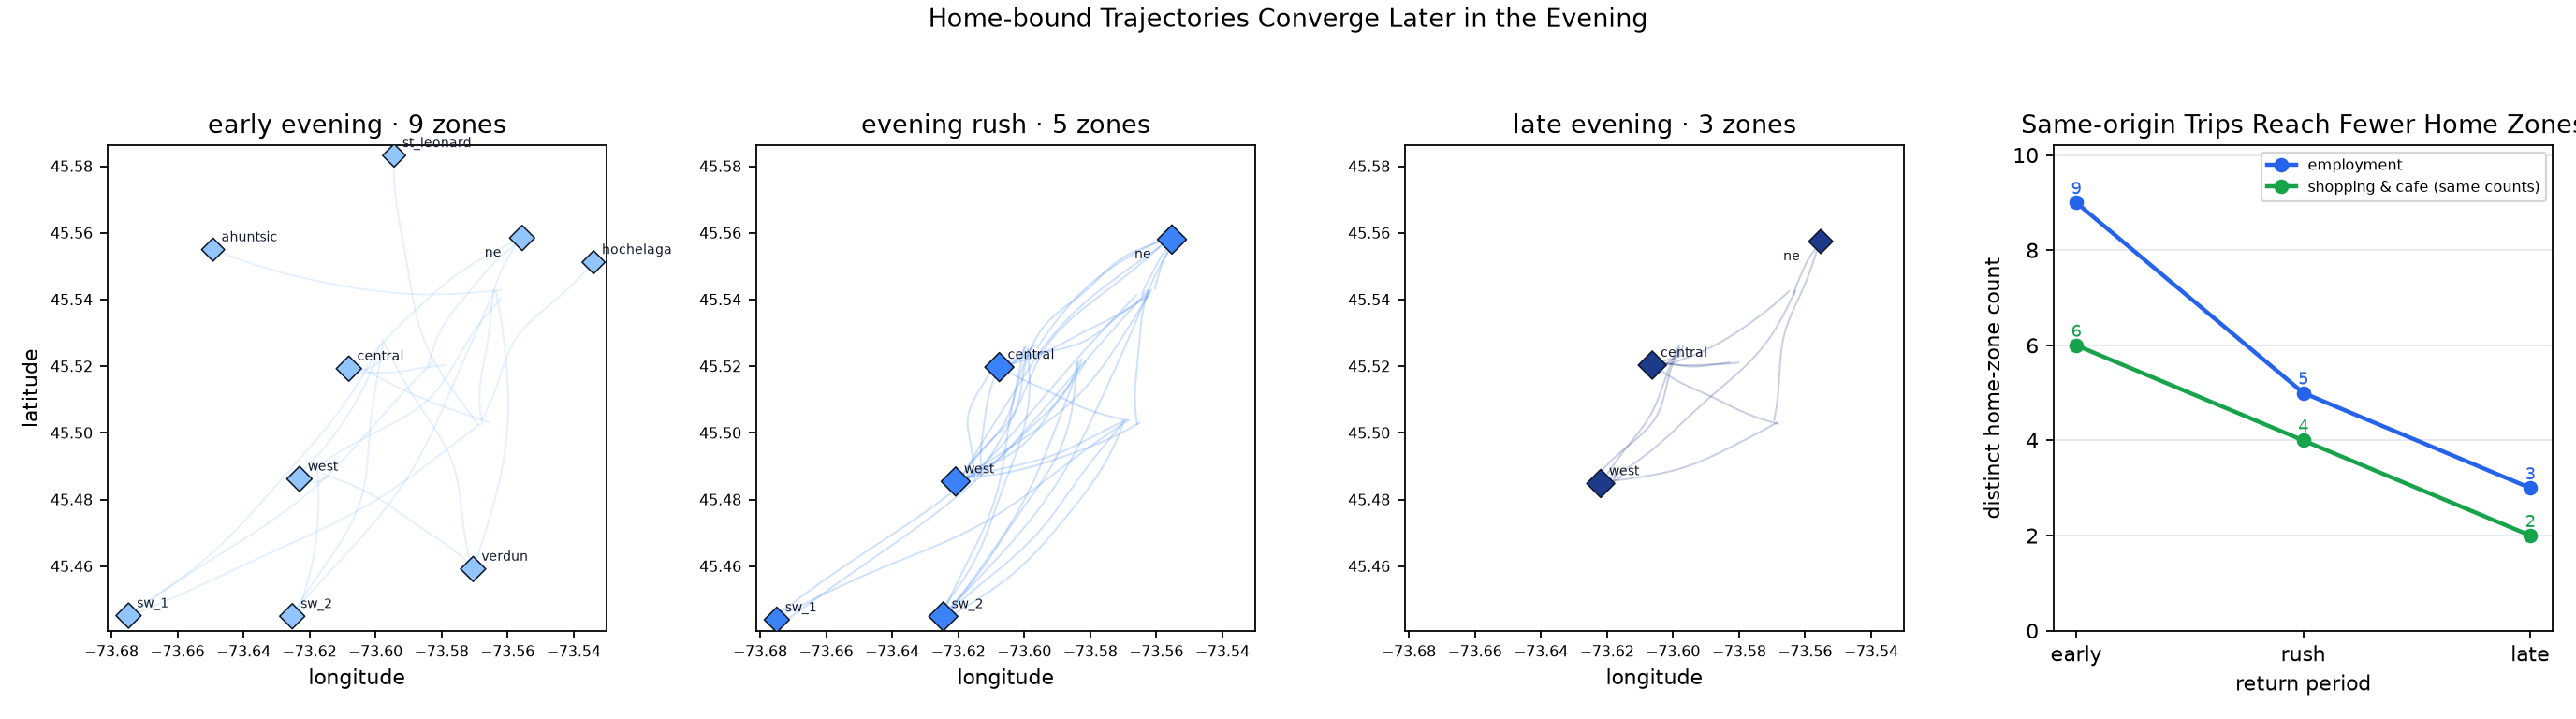

In [ ]:
df[df.purpose_group.eq('return_home')].groupby(['origin_land_use','return_period']).destination_zone.nunique()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/home_destination_convergence.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "home_destination_convergence",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Evening Home-destination Convergence",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/home_destination_convergence.png"
  },
  "question": "Does the number of home destination zones decline from early to late evening within each origin land-use?",
  "code": "df[df.purpose_group.eq('return_home')].groupby(['origin_land_use','return_period']).destination_zone.nunique()",
  "insight": "Home-bound trajectories from similar origin land-use increasingly converge toward a smaller set of residential or mixed destination areas as evening progresses.",
  "insight_type": "factor_relationship",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "origin_land_use",
    "destination_land_use",
    "gps_position",
    "trajectory_timestamp",
    "trajectory_id"
  ]
}

### Summary of Findings (Flag 16)

Returning-home travel is evening-concentrated and generally opposes morning work movement along Montréal's island axis. Employment-origin home trips are longer and more consistently motorized, while later home-bound trips converge on fewer destination areas.